# Trabajo Práctico N° 2

**Materia:** Minería de Datos
**Año:** 2026
**Integrantes:** Franco Renna y Franco Esparza

**Parte A:** regresión sobre `1000_Companies.csv`, para estimar `Profit`.
**Parte B:** clasificación sobre `drugType.csv`, para estimar `Droga`.

Usamos `random_state=63` en las particiones y en los árboles.

## Configuración

In [1]:
# Manejo de datos
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Preparación de datos
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import (StandardScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer)

# Modelos y métricas
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             accuracy_score, precision_score, recall_score,
                             ConfusionMatrixDisplay)

# Semilla que indica el enunciado, usada en particiones y modelos
SEMILLA = 63

## Parte A: regresión

### A1. Preparación de los datos

Trabajamos con `1000_Companies.csv`, que tiene los gastos y la ganancia de 1000 empresas. Queremos estimar `Profit`.

In [2]:
empresas = pd.read_csv("1000_Companies.csv")

print("Tabla 1. Primeras filas del conjunto de empresas")
empresas.head()

Tabla 1. Primeras filas del conjunto de empresas


,RyD_Spend,Administration,MarketingSpend,State,Profit
0,165349.20,136897.80,471784.10,New York,192261.83
1,162597.70,151377.59,443898.53,California,191792.06
2,153441.51,101145.55,407934.54,Florida,191050.39
3,144372.41,118671.85,383199.62,New York,182901.99
4,142107.34,91391.77,366168.42,Florida,166187.94


In [3]:
empresas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   RyD_Spend       1000 non-null   float64
 1   Administration  1000 non-null   float64
 2   MarketingSpend  1000 non-null   float64
 3   State           1000 non-null   str    
 4   Profit          1000 non-null   float64
dtypes: float64(4), str(1)
memory usage: 39.2 KB


In [4]:
print("Tabla 2. Medidas resumen de las variables numéricas")
empresas.describe()

Tabla 2. Medidas resumen de las variables numéricas


,RyD_Spend,Administration,MarketingSpend,Profit
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,81668.927200,122963.897612,226205.058419,119546.164656
std,46537.567891,12613.927535,91578.393542,42888.633848
min,0.000000,51283.140000,0.000000,14681.400000
25%,43084.500000,116640.684850,150969.584600,85943.198543
50%,79936.000000,122421.612150,224517.887350,117641.466300
75%,124565.500000,129139.118000,308189.808525,155577.107425
max,165349.200000,321652.140000,471784.100000,476485.430000


El conjunto tiene 1000 filas y 5 columnas, sin valores faltantes. Hay tres gastos (`RyD_Spend`, `Administration` y `MarketingSpend`), el estado (`State`) y la ganancia (`Profit`).

En la Tabla 2 nos llaman la atención dos cosas. `Profit` llega a 476.485 cuando el percentil 75 es 155.577, y `Administration` llega a 321.652 cuando su percentil 75 es 129.139, así que hay valores muy por encima del resto. Además, `RyD_Spend` y `MarketingSpend` tienen mínimos en 0. Los tomamos como empresas que no gastaron en ese rubro.

In [5]:
print("Filas duplicadas:", empresas.duplicated().sum())

print("Tabla 3. Filas repetidas")
empresas[empresas.duplicated(keep=False)]

Filas duplicadas: 1
Tabla 3. Filas repetidas


,RyD_Spend,Administration,MarketingSpend,State,Profit
335,84533.0,122941.3141,231885.6935,California,121248.7116
755,84533.0,122941.3141,231885.6935,California,121248.7116


Hay dos filas iguales en las cinco columnas (Tabla 3). Las tomamos como un registro cargado dos veces y dejamos una sola, para que no pueda quedar la misma empresa en entrenamiento y en test.

In [6]:
empresas = empresas.drop_duplicates()
print("Muestras luego de eliminar duplicados:", len(empresas))

Muestras luego de eliminar duplicados: 999


#### Distribuciones

**Hipótesis previa:** pensamos que los gastos van a estar repartidos a lo largo de su rango y que `Profit` va a tener una forma parecida.

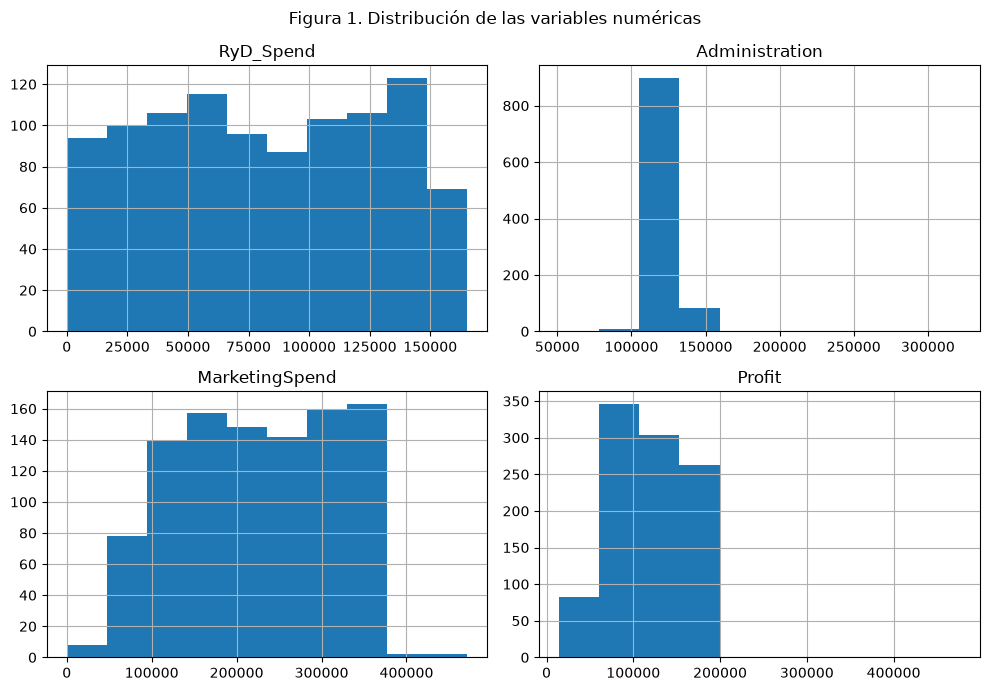

In [7]:
num_cols = ["RyD_Spend", "Administration", "MarketingSpend", "Profit"]

empresas[num_cols].hist(figsize=(10, 7))
plt.suptitle("Figura 1. Distribución de las variables numéricas")
plt.tight_layout()
plt.show()

La hipótesis se cumple en parte (Figura 1). `RyD_Spend` y `MarketingSpend` están bastante repartidos en su rango. `Administration` no: casi todas las empresas están entre 100.000 y 150.000 y casi no se ven barras más allá. `Profit` se concentra por debajo de 200.000 y el eje llega hasta más de 400.000 por unos pocos valores.

#### Correlaciones

**Hipótesis previa:** pensamos que los tres gastos se van a relacionar de forma positiva con la ganancia.

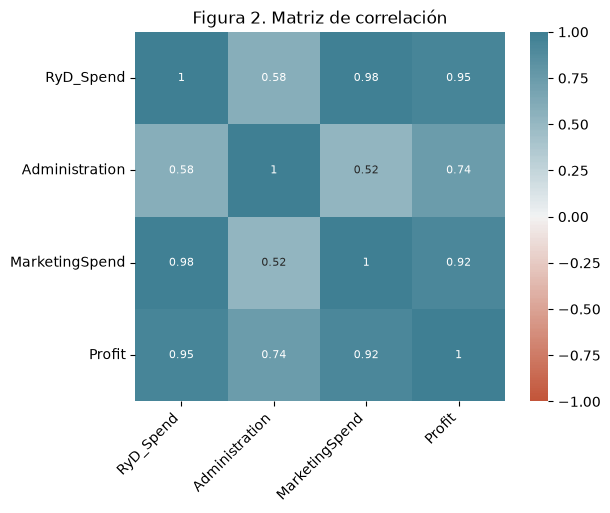

In [8]:
def plot_correlation_heatmap(corr, title):
    ax = sns.heatmap(
        corr,
        vmin=-1, vmax=1, center=0,
        cmap=sns.diverging_palette(20, 220, n=200),
        square=True,
        annot = True,
        annot_kws = {'size': 8})
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=45,
        horizontalalignment='right')
    plt.title(title)
    plt.show()


plot_correlation_heatmap(empresas[num_cols].corr(), "Figura 2. Matriz de correlación")

La hipótesis se cumple (Figura 2). `RyD_Spend` es la que más se relaciona con `Profit` (0.95), después `MarketingSpend` (0.92) y por último `Administration` (0.74). También vemos que `RyD_Spend` y `MarketingSpend` tienen 0.98 entre sí.

Para ver mejor estas relaciones graficamos cada gasto contra la ganancia.

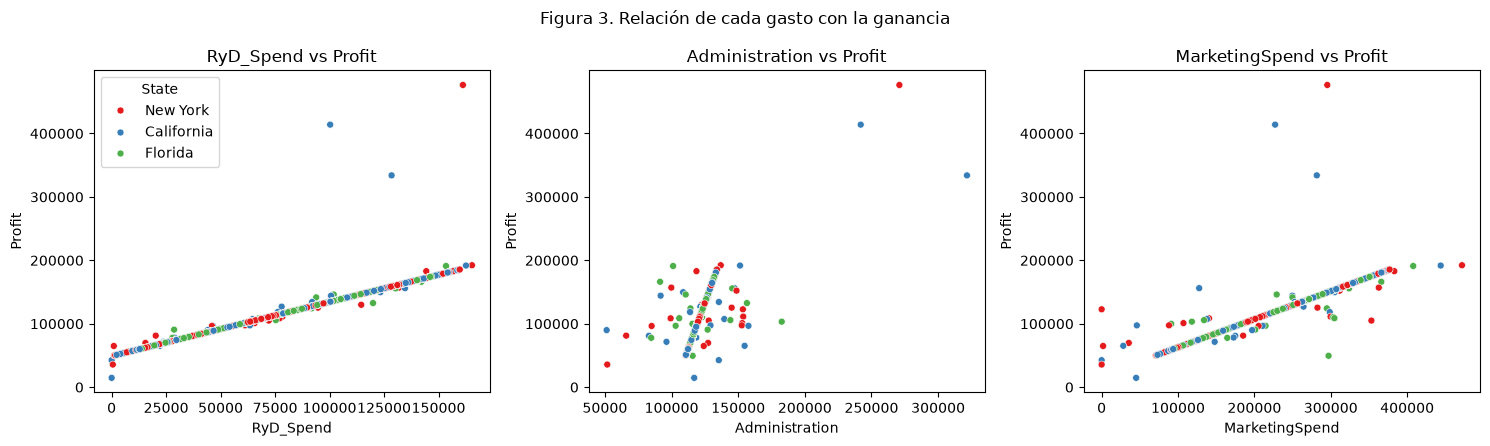

In [9]:
num_vars_graf = ["RyD_Spend", "Administration", "MarketingSpend"]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4.5))

for i, col in enumerate(num_vars_graf, 1):
    sns.scatterplot(data=empresas, x=col, y="Profit", hue="State", palette="Set1", s=25,
                    ax=axes.flatten()[i-1], legend=(i == 1))
    axes.flatten()[i-1].set_title(f"{col} vs Profit")

plt.suptitle("Figura 3. Relación de cada gasto con la ganancia")
plt.tight_layout()
plt.show()

En la Figura 3 vemos que:

- `RyD_Spend` contra `Profit` forma casi una recta.
- `MarketingSpend` también forma una recta, con más puntos sueltos.
- En `Administration` la mayoría forma una recta muy empinada, pero hay bastantes puntos dispersos alrededor.
- Los tres colores de `State` están mezclados en todos los gráficos, así que el estado no parece diferenciar a las empresas.

Además hay tres puntos muy por encima de todos los demás.

#### Valores atípicos

Contamos los valores fuera del rango de 1.5 × IQR en cada variable.

In [10]:
for col in num_cols:
    q1 = empresas[col].quantile(0.25)
    q3 = empresas[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = empresas[(empresas[col] < lower_bound) | (empresas[col] > upper_bound)]
    print(f"{col}: {len(outliers)} atípicos ({len(outliers)/len(empresas)*100:.1f}%) | límite superior {upper_bound:.2f}")

print()
print("Tabla 4. Empresas con mayor ganancia")
empresas.sort_values(by="Profit", ascending=False).head(3)

RyD_Spend: 0 atípicos (0.0%) | límite superior 246861.00
Administration: 22 atípicos (2.2%) | límite superior 147894.58
MarketingSpend: 0 atípicos (0.0%) | límite superior 545120.68
Profit: 3 atípicos (0.3%) | límite superior 260224.51

Tabla 4. Empresas con mayor ganancia


,RyD_Spend,Administration,MarketingSpend,State,Profit
999,161181.72,270939.86,295442.17,New York,476485.43
997,100275.47,241926.31,227142.82,California,413956.48
998,128456.23,321652.14,281692.32,California,333962.19


Encontramos dos casos y decidimos tratarlos distinto.

Los 3 atípicos de `Profit` los eliminamos. Son las tres últimas filas del archivo (Tabla 4) y son los puntos que en la Figura 3 quedan lejos de la recta. Como `Profit` es lo que queremos estimar, no queremos que esos tres casos influyan en el entrenamiento ni en la medición del error.

Los 22 atípicos de `Administration` los dejamos. Son gastos más altos de lo común, pero no vemos nada que indique que sean errores y no son la variable a estimar.

In [11]:
q1 = empresas["Profit"].quantile(0.25)
q3 = empresas["Profit"].quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)

empresas = empresas[empresas["Profit"] <= limite_superior]
print(f"Muestras luego de eliminar las empresas con ganancia atípica: {len(empresas)}")
print()
print("Tabla 5. Medidas resumen luego de la limpieza")
empresas[num_cols].describe()

Muestras luego de eliminar las empresas con ganancia atípica: 996

Tabla 5. Medidas resumen luego de la limpieza


,RyD_Spend,Administration,MarketingSpend,Profit
count,996.000000,996.000000,996.000000,996.000000
mean,81520.563032,122496.423682,226073.188168,118675.212695
std,46535.141677,9144.756564,91718.887094,39808.331643
min,0.000000,51283.140000,0.000000,14681.400000
25%,43056.000000,116636.180475,150136.039475,85839.615710
50%,79401.000000,122377.380650,223809.759850,117321.534150
75%,124079.000000,129060.069850,309128.511625,155032.518175
max,165349.200000,182645.560000,471784.100000,192261.830000


Nos quedan 996 empresas. En la Tabla 5 vemos que el máximo de `Profit` pasa de 476.485 a 192.262 y el de `Administration` de 321.652 a 182.646.

#### Separación en entrenamiento y test

Hacemos las dos particiones que pide el enunciado, 80/20 y 70/30. Codificamos y estandarizamos después de separar, ajustando solo con el entrenamiento, como vimos en la unidad 4.

In [12]:
X = empresas.drop(columns="Profit")
y = empresas["Profit"]

num_vars = ["RyD_Spend", "Administration", "MarketingSpend"]
cat_vars = ["State"]


def preparar(test_size):
    Xtrn, Xtst, ytrn, ytst = train_test_split(X, y, test_size=test_size,
                                              random_state=SEMILLA, shuffle=True)

    # State no tiene orden, así que usamos una columna por estado
    enc = OneHotEncoder(sparse_output=False).set_output(transform="pandas")
    enc.fit(Xtrn[cat_vars])
    Xtrn = pd.concat([Xtrn[num_vars], enc.transform(Xtrn[cat_vars])], axis=1)
    Xtst = pd.concat([Xtst[num_vars], enc.transform(Xtst[cat_vars])], axis=1)

    # El escalador se ajusta solo con el entrenamiento
    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(Xtrn[num_vars])
    Xtrn_std = Xtrn.copy()
    Xtst_std = Xtst.copy()
    Xtrn_std[num_vars] = scaler.transform(Xtrn[num_vars])
    Xtst_std[num_vars] = scaler.transform(Xtst[num_vars])

    return {"Xtrn": Xtrn, "Xtst": Xtst, "ytrn": ytrn, "ytst": ytst,
            "Xtrn_std": Xtrn_std, "Xtst_std": Xtst_std}


particiones = {"80/20": preparar(0.2), "70/30": preparar(0.3)}

for nombre in particiones:
    p = particiones[nombre]
    print(f"{nombre}: entrenamiento {len(p['Xtrn'])} muestras | test {len(p['Xtst'])} muestras")

print()
print("Tabla 6. Variables luego de codificar State")
particiones["80/20"]["Xtrn"].head()

80/20: entrenamiento 796 muestras | test 200 muestras
70/30: entrenamiento 697 muestras | test 299 muestras

Tabla 6. Variables luego de codificar State


,RyD_Spend,Administration,MarketingSpend,State_California,State_Florida,State_New York
398,12412.0,112290.1563,92728.02707,1.0,0.0,0.0
794,12564.0,112312.6043,93021.31149,1.0,0.0,0.0
102,127529.0,129291.1592,314846.59290,0.0,1.0,0.0
883,64529.0,119987.0323,193287.92090,1.0,0.0,0.0
219,10758.0,112045.8860,89536.62956,1.0,0.0,0.0


Las particiones quedan con 796 y 200 muestras la primera, y con 697 y 299 la segunda. `State` pasó a ser tres columnas de 0 y 1 (Tabla 6), porque los estados no tienen un orden.

Los árboles los entrenamos con las variables sin estandarizar, igual que en los notebooks de la unidad 4, para poder leer los umbrales en las unidades originales.

### A2. Árbol de decisión para regresión

**Hipótesis previa:** como en la Figura 3 `RyD_Spend` formaba casi una recta con `Profit`, pensamos que el árbol va a usar sobre todo esa variable y que el error va a ser bajo comparado con la ganancia media de 118.675 (Tabla 5).

Probamos las combinaciones con `GridSearchCV` sobre el entrenamiento, con los valores de la grilla del notebook de la unidad 4. Elegimos según el error cuadrático medio, que es una de las métricas que pide el enunciado.

In [13]:
grilla = {
    "max_depth": [3, 5, 10, None],
    "min_samples_leaf": [1, 5, 10],
    "min_samples_split": [2, 5, 10],
}

busquedas = {}
for nombre in particiones:
    p = particiones[nombre]
    busqueda = GridSearchCV(DecisionTreeRegressor(random_state=SEMILLA), grilla,
                            cv=5, scoring="neg_mean_squared_error")
    busqueda.fit(p["Xtrn"], p["ytrn"])
    busquedas[nombre] = busqueda
    arbol = busqueda.best_estimator_
    print(f"{nombre} -> {busqueda.best_params_}")
    print(f"   RMSE de validación cruzada: {np.sqrt(-busqueda.best_score_):.2f}"
          f" | profundidad: {arbol.get_depth()} | hojas: {arbol.get_n_leaves()}")

resultados_cv = pd.DataFrame(busquedas["80/20"].cv_results_)
resultados_cv["RMSE_cv"] = np.sqrt(-resultados_cv["mean_test_score"])

print()
print("Tabla 7. Mejores combinaciones en la partición 80/20")
resultados_cv.sort_values("rank_test_score")[
    ["param_max_depth", "param_min_samples_leaf", "param_min_samples_split", "RMSE_cv"]
].head(6).round(0)

80/20 -> {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
   RMSE de validación cruzada: 2240.58 | profundidad: 10 | hojas: 141


70/30 -> {'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
   RMSE de validación cruzada: 2435.21 | profundidad: 8 | hojas: 106

Tabla 7. Mejores combinaciones en la partición 80/20


,param_max_depth,param_min_samples_leaf,param_min_samples_split,RMSE_cv
29,None,1,10,2241.0
20,10,1,10,2241.0
23,10,5,10,2261.0
22,10,5,5,2261.0
31,None,5,5,2261.0
21,10,5,2,2261.0


Las dos particiones eligen `max_depth=10`, pero difieren en lo demás: la 80/20 elige `min_samples_leaf=1` y `min_samples_split=10`, y la 70/30 `min_samples_leaf=5` y `min_samples_split=2`. Los árboles tienen 141 y 106 hojas.

En la Tabla 7 las dos primeras combinaciones tienen un RMSE de 2241 y las cuatro siguientes de 2261. Como la diferencia es muy chica, la elección dentro de estas combinaciones casi no cambia el resultado.

In [14]:
importancias = pd.DataFrame({
    "variable": particiones["80/20"]["Xtrn"].columns,
    "importancia": busquedas["80/20"].best_estimator_.feature_importances_,
}).sort_values("importancia", ascending=False)

print("Tabla 8. Importancia de cada variable en el árbol (partición 80/20)")
importancias.round(4)

Tabla 8. Importancia de cada variable en el árbol (partición 80/20)


,variable,importancia
0,RyD_Spend,0.9890
2,MarketingSpend,0.0065
1,Administration,0.0045
3,State_California,0.0000
4,State_Florida,0.0000
5,State_New York,0.0000


La hipótesis se cumple: en la Tabla 8 `RyD_Spend` tiene una importancia de 0.989. `MarketingSpend` y `Administration` casi no aportan y las tres columnas de `State` quedan en 0. Coincide con lo que vimos en la Figura 3.

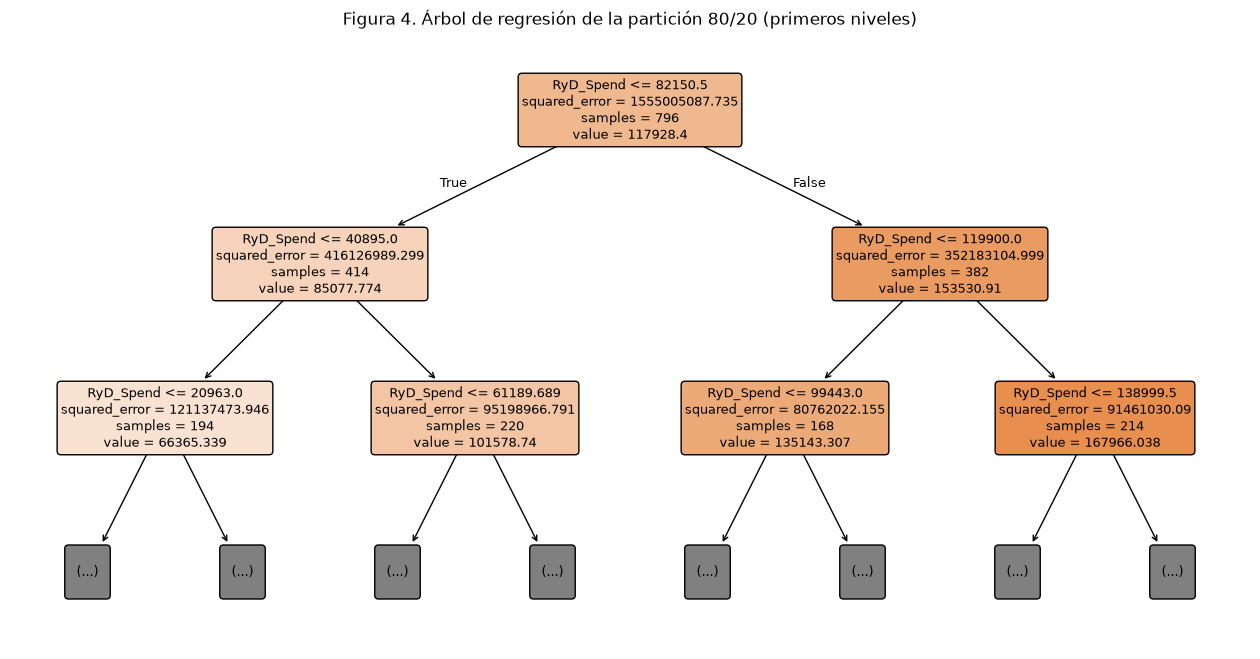

In [15]:
plt.figure(figsize=(16, 8))
plot_tree(busquedas["80/20"].best_estimator_, max_depth=2,
          feature_names=particiones["80/20"]["Xtrn"].columns,
          filled=True, rounded=True, fontsize=9)
plt.title("Figura 4. Árbol de regresión de la partición 80/20 (primeros niveles)")
plt.show()

Mostramos solo los primeros niveles porque con 141 hojas no se puede leer.

En la Figura 4 todas las divisiones usan `RyD_Spend`. La primera corta en 82150.5 y deja 414 empresas de un lado, con una ganancia media de 85.078, y 382 del otro, con 153.531.

In [16]:
filas = []
for nombre in particiones:
    p = particiones[nombre]
    pred = busquedas[nombre].best_estimator_.predict(p["Xtst"])
    mse = mean_squared_error(p["ytst"], pred)
    filas.append({
        "partición": nombre,
        "muestras de test": len(p["ytst"]),
        "MAE": mean_absolute_error(p["ytst"], pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
    })

metricas_reg = pd.DataFrame(filas)

print("Tabla 9. Métricas sobre los conjuntos de test")
metricas_reg.round(2)

Tabla 9. Métricas sobre los conjuntos de test


,partición,muestras de test,MAE,MSE,RMSE
0,80/20,200,997.20,12853559.57,3585.19
1,70/30,299,949.77,8354923.35,2890.49


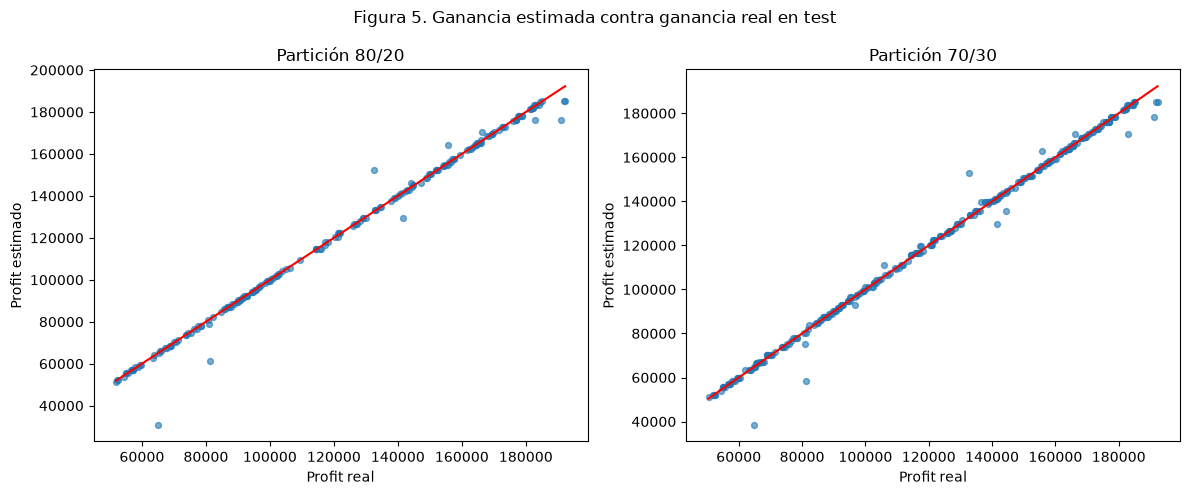

In [17]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))

for i, nombre in enumerate(particiones, 1):
    p = particiones[nombre]
    ax = axes.flatten()[i-1]
    pred = busquedas[nombre].best_estimator_.predict(p["Xtst"])
    ax.scatter(p["ytst"], pred, s=18, alpha=0.6)
    ax.plot([p["ytst"].min(), p["ytst"].max()], [p["ytst"].min(), p["ytst"].max()], color="red")
    ax.set_xlabel("Profit real")
    ax.set_ylabel("Profit estimado")
    ax.set_title(f"Partición {nombre}")

plt.suptitle("Figura 5. Ganancia estimada contra ganancia real en test")
plt.tight_layout()
plt.show()

La hipótesis se cumple. En la Tabla 9 el MAE es 997.20 en la 80/20 y 949.77 en la 70/30, valores chicos comparados con la ganancia media de 118.675 (Tabla 5).

El RMSE es bastante más alto que el MAE (3585.19 y 2890.49). En la Figura 5 vemos que casi todos los puntos están sobre la línea roja y unos pocos quedan lejos, que son los que más suben el RMSE.

La 70/30 da mejores valores en las tres métricas, aunque entrena con menos empresas (697 contra 796).

## Parte B: clasificación

### B3. Preparación de los datos

Trabajamos con `drugType.csv`, que tiene datos de 200 pacientes y la droga indicada a cada uno. Queremos estimar `Droga`.

In [18]:
pacientes = pd.read_csv("drugType.csv")

print("Tabla 10. Primeras filas del conjunto de pacientes")
pacientes.head()

Tabla 10. Primeras filas del conjunto de pacientes

,Edad,Sexo,BP,Colesterol,Na_a_K,Droga
0,23,F,Alto,Alto,25.355,DrogaY
1,47,M,Bajo,Alto,13.093,DrogaC
2,47,M,Bajo,Alto,10.114,DrogaC
3,28,F,Normal,Alto,7.798,DrogaX
4,61,F,Bajo,Alto,18.043,DrogaY


In [19]:
pacientes.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Edad        200 non-null    int64  
 1   Sexo        200 non-null    str    
 2   BP          200 non-null    str    
 3   Colesterol  200 non-null    str    
 4   Na_a_K      200 non-null    float64
 5   Droga       200 non-null    str    
dtypes: float64(1), int64(1), str(4)
memory usage: 9.5 KB


In [20]:
print("Filas duplicadas:", pacientes.duplicated().sum())
print()
print("Tabla 11. Medidas resumen de las variables numéricas")
pacientes.describe()

Filas duplicadas: 0

Tabla 11. Medidas resumen de las variables numéricas


,Edad,Na_a_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


Son 200 pacientes y 6 columnas, sin valores faltantes ni filas duplicadas. Hay dos variables numéricas, `Edad` (de 15 a 74) y `Na_a_K` (de 6.27 a 38.25), tres categóricas (`Sexo`, `BP` y `Colesterol`) y la variable a estimar, `Droga`.

#### Distribución de la variable objetivo

**Hipótesis previa:** pensamos que algunas drogas se van a indicar más que otras.

Tabla 12. Balance de clases
        Cantidad  Porcentaje
Droga                       
DrogaY        91        45.5
DrogaX        54        27.0
DrogaA        23        11.5
DrogaC        16         8.0
DrogaB        16         8.0


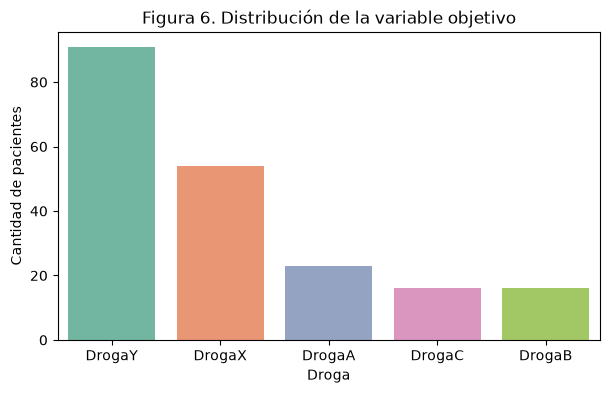

In [21]:
balance = pd.DataFrame({
    "Cantidad": pacientes["Droga"].value_counts(),
    "Porcentaje": (pacientes["Droga"].value_counts(normalize=True) * 100).round(1),
})

print("Tabla 12. Balance de clases")
print(balance)

plt.figure(figsize=(7, 4))
sns.barplot(x=balance.index, y=balance["Cantidad"], hue=balance.index,
            palette="Set2", legend=False)
plt.ylabel("Cantidad de pacientes")
plt.title("Figura 6. Distribución de la variable objetivo")
plt.show()

La hipótesis se cumple (Tabla 12 y Figura 6). DrogaY tiene el 45.5% de los pacientes y DrogaX el 27%, mientras que DrogaC y DrogaB tienen 16 pacientes cada una (8%).

Por este desbalance hacemos las particiones estratificadas, para que las drogas con pocos pacientes aparezcan en los dos conjuntos.

#### Variables numéricas

**Hipótesis previa:** si estas variables influyen en la droga indicada, cada droga debería tener rangos distintos de `Edad` o de `Na_a_K`.

Tabla 13. Edad y Na_a_K según la droga
       Edad           Na_a_K            
        min  mean max    min  mean   max
Droga                                   
DrogaA   19  35.9  50    6.3  10.9  14.0
DrogaB   51  62.5  74    8.6  11.5  14.2
DrogaC   16  42.5  72    6.8  10.6  14.2
DrogaX   15  44.0  74    6.7  10.7  14.6
DrogaY   15  43.7  74   15.0  22.4  38.2


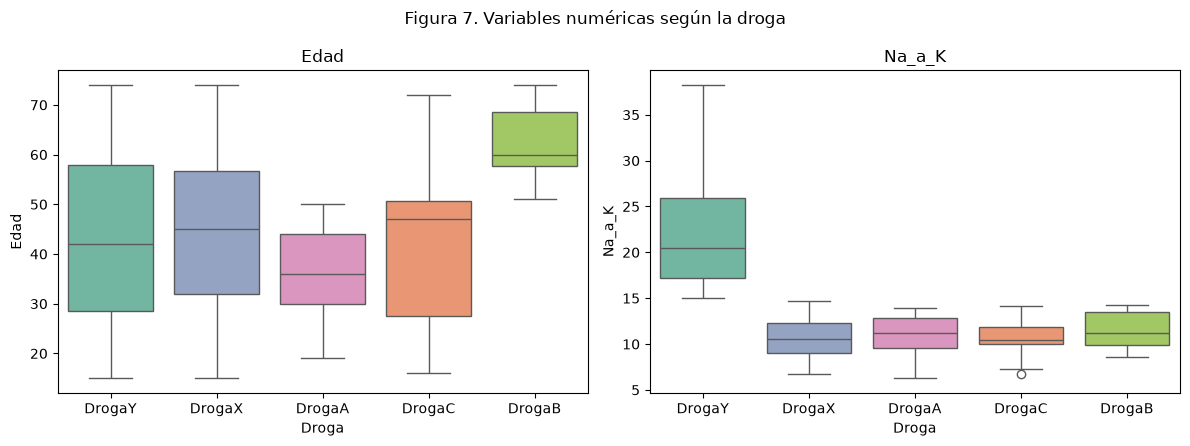

In [22]:
resumen_num = pacientes.groupby("Droga")[["Edad", "Na_a_K"]].agg(["min", "mean", "max"]).round(1)

print("Tabla 13. Edad y Na_a_K según la droga")
print(resumen_num)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

for i, col in enumerate(["Edad", "Na_a_K"], 1):
    sns.boxplot(data=pacientes, x="Droga", y=col, order=balance.index,
                hue="Droga", palette="Set2", legend=False, ax=axes.flatten()[i-1])
    axes.flatten()[i-1].set_title(col)

plt.suptitle("Figura 7. Variables numéricas según la droga")
plt.tight_layout()
plt.show()

La hipótesis se cumple solo en algunos casos:

- `Na_a_K` separa a DrogaY: en la Tabla 13 su mínimo es 15.0 y el máximo de las otras drogas es 14.6. En la Figura 7 su caja queda arriba de las demás.
- `Edad` diferencia a DrogaB, cuyo mínimo es 51, mientras que las otras empiezan entre 15 y 19.
- Las otras drogas tienen rangos parecidos en las dos variables.

#### Variables categóricas

**Hipótesis previa:** pensamos que la presión y el colesterol van a estar relacionados con la droga, y el sexo no.

Sexo contra Droga
Droga  DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Sexo                                         
F           9       6       7      27      47
M          14      10       9      27      44

BP contra Droga
Droga   DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
BP                                            
Alto        23      16       0       0      38
Bajo         0       0      16      18      30
Normal       0       0       0      36      23

Colesterol contra Droga
Droga       DrogaA  DrogaB  DrogaC  DrogaX  DrogaY
Colesterol                                        
Alto            12       8      16      20      47
Normal          11       8       0      34      44



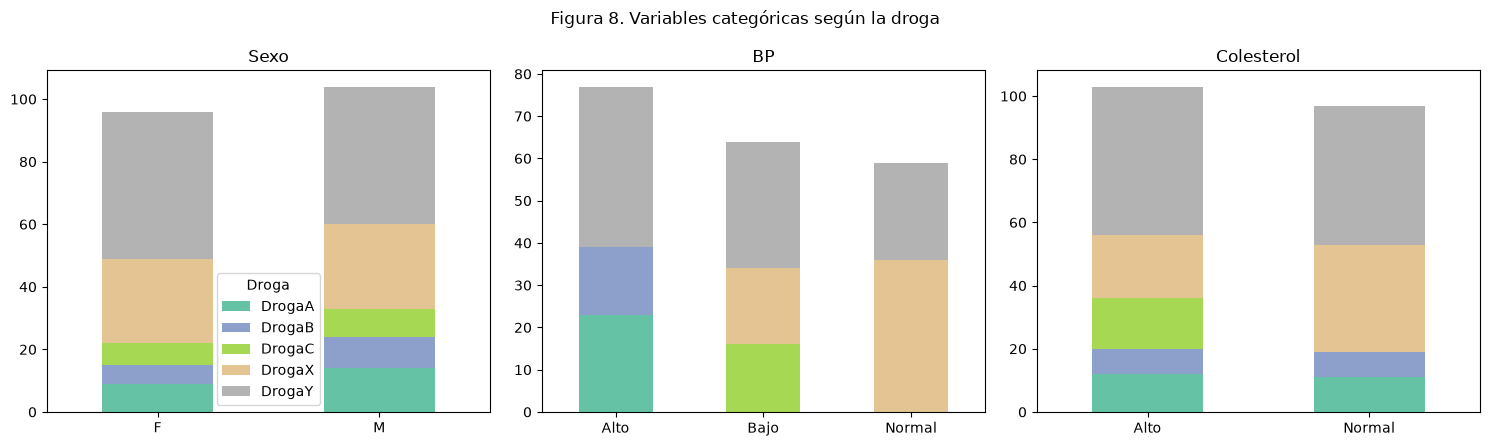

In [23]:
for col in ["Sexo", "BP", "Colesterol"]:
    print(f"{col} contra Droga")
    print(pd.crosstab(pacientes[col], pacientes["Droga"]))
    print()

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 4.5))

for i, col in enumerate(["Sexo", "BP", "Colesterol"], 1):
    pd.crosstab(pacientes[col], pacientes["Droga"]).plot(
        kind="bar", stacked=True, ax=axes.flatten()[i-1], colormap="Set2",
        legend=(i == 1), rot=0)
    axes.flatten()[i-1].set_title(col)
    axes.flatten()[i-1].set_xlabel("")

plt.suptitle("Figura 8. Variables categóricas según la droga")
plt.tight_layout()
plt.show()

La hipótesis se cumple (Figura 8 y tablas anteriores):

- En `BP`, DrogaA (23) y DrogaB (16) aparecen solo con presión alta, DrogaC (16) solo con presión baja y DrogaX nunca con presión alta.
- En `Colesterol`, DrogaC aparece solo con colesterol alto.
- En `Sexo`, las drogas se reparten de forma parecida.

#### Valores atípicos

Contamos los atípicos con el mismo criterio de la Parte A.

In [24]:
for columna in ["Edad", "Na_a_K"]:
    q1 = pacientes[columna].quantile(0.25)
    q3 = pacientes[columna].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = pacientes[(pacientes[columna] < lower_bound) | (pacientes[columna] > upper_bound)]
    print(f"{columna}: {len(outliers)} atípicos | límite superior {upper_bound:.1f}")
    if len(outliers) > 0:
        print(outliers["Droga"].value_counts().to_string())

Edad: 0 atípicos | límite superior 98.5
Na_a_K: 8 atípicos | límite superior 32.8
Droga
DrogaY    8


`Edad` no tiene atípicos y `Na_a_K` tiene 8, todos de DrogaY. No los eliminamos porque son valores altos de la variable que identifica a esa droga (Figura 7).

#### Codificación y particiones

`BP` y `Colesterol` tienen un orden (Bajo < Normal < Alto), así que los codificamos respetándolo, igual que `Sexo`. `Droga` queda como texto para leer mejor las matrices de confusión. El codificador y el escalador se ajustan solo con el entrenamiento y las particiones llevan `stratify`.

In [25]:
X_pac = pacientes.drop(columns="Droga")
y_pac = pacientes["Droga"]

num_pac = ["Edad", "Na_a_K"]
cat_pac = ["Sexo", "BP", "Colesterol"]

# Orden de cada categoría
categorias = [
    ["F", "M"],                  # Sexo
    ["Bajo", "Normal", "Alto"],  # BP
    ["Normal", "Alto"],          # Colesterol
]


def preparar_pacientes(test_size):
    Xtrn, Xtst, ytrn, ytst = train_test_split(X_pac, y_pac, test_size=test_size,
                                              random_state=SEMILLA, shuffle=True,
                                              stratify=y_pac)

    enc = OrdinalEncoder(categories=categorias).set_output(transform="pandas")
    enc.fit(Xtrn[cat_pac])
    Xtrn[cat_pac] = enc.transform(Xtrn[cat_pac])
    Xtst[cat_pac] = enc.transform(Xtst[cat_pac])

    scaler = StandardScaler().set_output(transform="pandas")
    scaler.fit(Xtrn[num_pac])
    Xtrn_std = Xtrn.copy()
    Xtst_std = Xtst.copy()
    Xtrn_std[num_pac] = scaler.transform(Xtrn[num_pac])
    Xtst_std[num_pac] = scaler.transform(Xtst[num_pac])

    return {"Xtrn": Xtrn, "Xtst": Xtst, "ytrn": ytrn, "ytst": ytst,
            "Xtrn_std": Xtrn_std, "Xtst_std": Xtst_std}


particiones_pac = {"80/20": preparar_pacientes(0.2), "70/30": preparar_pacientes(0.3)}

for nombre in particiones_pac:
    p = particiones_pac[nombre]
    print(f"{nombre}: entrenamiento {len(p['Xtrn'])} pacientes | test {len(p['Xtst'])} pacientes")

proporciones = pd.DataFrame({
    "conjunto completo": y_pac.value_counts(normalize=True),
    "train 80/20": particiones_pac["80/20"]["ytrn"].value_counts(normalize=True),
    "test 80/20": particiones_pac["80/20"]["ytst"].value_counts(normalize=True),
    "test 70/30": particiones_pac["70/30"]["ytst"].value_counts(normalize=True),
}).round(3) * 100

print()
print("Tabla 14. Porcentaje de cada clase en los conjuntos")
proporciones

80/20: entrenamiento 160 pacientes | test 40 pacientes
70/30: entrenamiento 140 pacientes | test 60 pacientes

Tabla 14. Porcentaje de cada clase en los conjuntos


,conjunto completo,train 80/20,test 80/20,test 70/30
Droga,,,,
DrogaA,11.5,11.2,12.5,11.7
DrogaB,8.0,8.1,7.5,8.3
DrogaC,8.0,8.1,7.5,8.3
DrogaX,27.0,26.9,27.5,26.7
DrogaY,45.5,45.6,45.0,45.0


Las particiones quedan con 160 y 40 pacientes la primera, y con 140 y 60 la segunda. En la Tabla 14 vemos que los porcentajes de cada droga son muy parecidos a los del conjunto completo, así que la estratificación funcionó.

### B4. Árbol de decisión para clasificación

**Hipótesis previa:** como `Na_a_K`, `BP` y `Edad` separaban bien a las drogas (Figuras 7 y 8), pensamos que un árbol poco profundo va a tener una exactitud muy alta.

Usamos la misma grilla de la Parte A porque el enunciado pide los mismos tres hiperparámetros, y elegimos con `f1_weighted`, como el notebook de árboles de clasificación de la unidad 4.

In [26]:
busquedas_pac = {}

for nombre in particiones_pac:
    p = particiones_pac[nombre]
    busqueda = GridSearchCV(DecisionTreeClassifier(random_state=SEMILLA), grilla,
                            cv=5, scoring="f1_weighted")
    busqueda.fit(p["Xtrn"], p["ytrn"])
    busquedas_pac[nombre] = busqueda
    arbol = busqueda.best_estimator_
    print(f"{nombre} -> {busqueda.best_params_}")
    print(f"   f1 de validación cruzada: {busqueda.best_score_:.4f}"
          f" | profundidad: {arbol.get_depth()} | hojas: {arbol.get_n_leaves()}")

resultados_pac = pd.DataFrame(busquedas_pac["80/20"].cv_results_)
empatadas = (resultados_pac["mean_test_score"].round(6)
             == round(busquedas_pac["80/20"].best_score_, 6)).sum()

print()
print(f"Combinaciones que empatan en el mejor f1: {empatadas} de {len(resultados_pac)}")
print()
print("Tabla 15. Mejores combinaciones en la partición 80/20")
resultados_pac.sort_values("rank_test_score")[
    ["param_max_depth", "param_min_samples_leaf", "param_min_samples_split", "mean_test_score"]
].head(6).round(4)

80/20 -> {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
   f1 de validación cruzada: 0.9868 | profundidad: 4 | hojas: 6


70/30 -> {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
   f1 de validación cruzada: 0.9729 | profundidad: 4 | hojas: 6

Combinaciones que empatan en el mejor f1: 27 de 36

Tabla 15. Mejores combinaciones en la partición 80/20


,param_max_depth,param_min_samples_leaf,param_min_samples_split,mean_test_score
12,5,5,2,0.9868
15,5,10,2,0.9868
13,5,5,5,0.9868
14,5,5,10,0.9868
10,5,1,5,0.9868
11,5,1,10,0.9868


Las dos particiones eligen `max_depth=5`, `min_samples_leaf=1` y `min_samples_split=2`, con un f1 de 0.9868 y 0.9729. El árbol llega a profundidad 4 y tiene 6 hojas.

En la 80/20, 27 de las 36 combinaciones empatan en el mejor f1, y por eso el orden de la Tabla 15 no nos dice cuál es mejor.

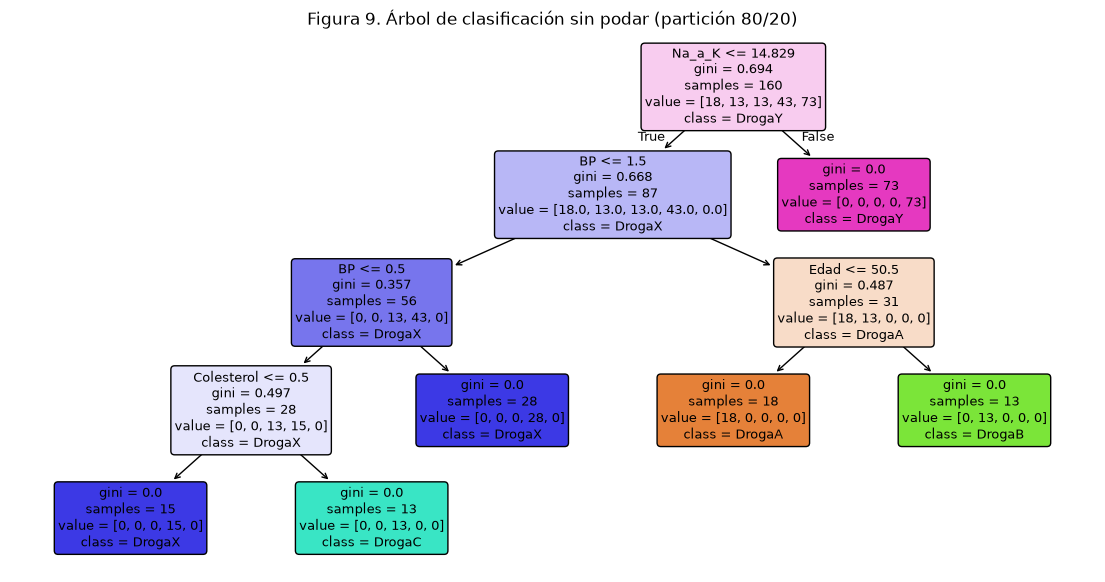

In [27]:
arbol_pac = busquedas_pac["80/20"].best_estimator_

plt.figure(figsize=(14, 7))
plot_tree(arbol_pac, feature_names=particiones_pac["80/20"]["Xtrn"].columns,
          class_names=arbol_pac.classes_, filled=True, rounded=True, fontsize=9)
plt.title("Figura 9. Árbol de clasificación sin podar (partición 80/20)")
plt.show()

En la Figura 9 vemos las reglas que aparecían en el análisis exploratorio:

1. `Na_a_K <= 14.829`: los 73 pacientes que lo superan son todos DrogaY.
2. `BP <= 1.5`: con presión alta quedan DrogaA y DrogaB; con baja o normal, DrogaX y DrogaC.
3. `Edad <= 50.5` separa DrogaA (18) de DrogaB (13).
4. `BP <= 0.5`: con presión normal quedan 28 pacientes, todos de DrogaX.
5. `Colesterol <= 0.5`, con presión baja, separa DrogaX (15) de DrogaC (13).

`Sexo` no aparece en ninguna división, como esperábamos por la Figura 8. Las seis hojas tienen `gini = 0.0`.

#### Post-poda

Probamos distintos valores de `ccp_alpha` con validación cruzada sobre el entrenamiento de la 80/20, partiendo de los hiperparámetros elegidos. Los valores los elegimos nosotros, desde 0 hasta uno que deje pocas hojas.

In [28]:
p = particiones_pac["80/20"]

grilla_poda = {"ccp_alpha": [0, 0.01, 0.05, 0.07, 0.1, 0.15]}

busqueda_poda = GridSearchCV(
    DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, min_samples_split=2,
                           random_state=SEMILLA),
    grilla_poda, cv=5, scoring="f1_weighted")
busqueda_poda.fit(p["Xtrn"], p["ytrn"])

filas_poda = []
for i, alpha in enumerate(grilla_poda["ccp_alpha"]):
    podado = DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, min_samples_split=2,
                                    ccp_alpha=alpha, random_state=SEMILLA)
    podado.fit(p["Xtrn"], p["ytrn"])
    filas_poda.append({
        "ccp_alpha": alpha,
        "f1 validación cruzada": busqueda_poda.cv_results_["mean_test_score"][i],
        "hojas": podado.get_n_leaves(),
        "clases que predice": len(np.unique(podado.predict(p["Xtrn"]))),
    })

print("Tabla 16. Valores de ccp_alpha evaluados")
pd.DataFrame(filas_poda).round(4)

Tabla 16. Valores de ccp_alpha evaluados


,ccp_alpha,f1 validación cruzada,hojas,clases que predice
0,0.00,0.9868,6,5
1,0.01,0.9868,6,5
2,0.05,0.9868,6,5
3,0.07,0.8705,4,4
4,0.10,0.7665,3,3
5,0.15,0.6283,2,2


Elegimos `ccp_alpha = 0`, o sea no podar. En la Tabla 16, con 0.01 y 0.05 el árbol no cambia (6 hojas y f1 de 0.9868). Con 0.07 el f1 baja a 0.8705 y el árbol pasa a 4 hojas y 4 clases, y sigue bajando con los valores más altos. Para ver el efecto graficamos el árbol con 0.07.

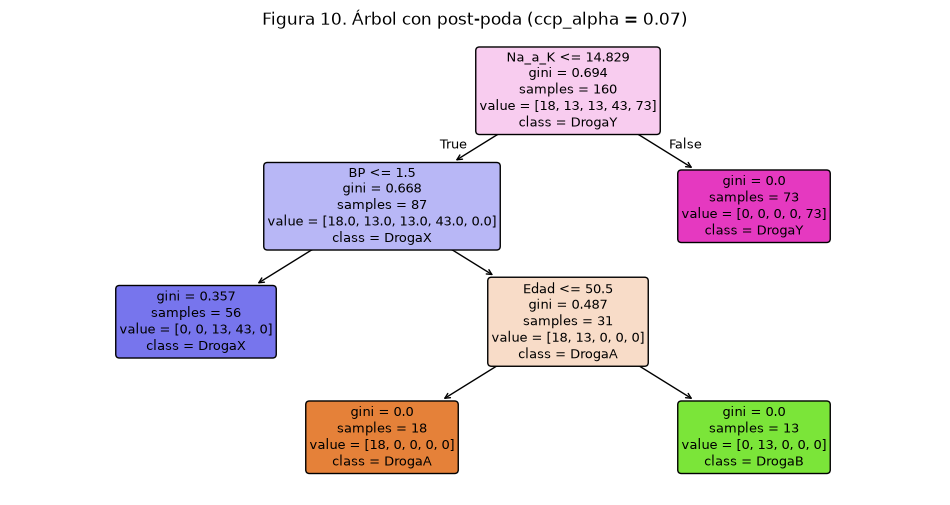

In [29]:
arbol_podado = DecisionTreeClassifier(max_depth=5, min_samples_leaf=1, min_samples_split=2,
                                      ccp_alpha=0.07, random_state=SEMILLA)
arbol_podado.fit(p["Xtrn"], p["ytrn"])

plt.figure(figsize=(12, 6))
plot_tree(arbol_podado, feature_names=p["Xtrn"].columns,
          class_names=arbol_podado.classes_, filled=True, rounded=True, fontsize=9)
plt.title("Figura 10. Árbol con post-poda (ccp_alpha = 0.07)")
plt.show()

En la Figura 10 se fueron las divisiones `BP <= 0.5` y `Colesterol <= 0.5`. Los 56 pacientes con presión baja o normal quedan en una sola hoja de DrogaX, y 13 de ellos son de DrogaC. El árbol podado ya no puede predecir DrogaC, lo que confirma nuestra elección de no podar.

#### Resultados sobre los conjuntos de test

In [30]:
def calcular_metricas(nombre, ytst, pred):
    return {
        "partición": nombre,
        "Exactitud": accuracy_score(ytst, pred),
        "Precisión (macro)": precision_score(ytst, pred, average="macro"),
        "Exhaustividad (macro)": recall_score(ytst, pred, average="macro"),
    }


filas_clasif = []
predicciones_arbol = {}

for nombre in particiones_pac:
    p = particiones_pac[nombre]
    predicciones_arbol[nombre] = busquedas_pac[nombre].best_estimator_.predict(p["Xtst"])
    filas_clasif.append(calcular_metricas(nombre, p["ytst"], predicciones_arbol[nombre]))

metricas_arbol = pd.DataFrame(filas_clasif)

print("Tabla 17. Métricas del árbol de clasificación sobre los test")
metricas_arbol.round(4)

Tabla 17. Métricas del árbol de clasificación sobre los test

,partición,Exactitud,Precisión (macro),Exhaustividad (macro)
0,80/20,1.0,1.0,1.0
1,70/30,1.0,1.0,1.0


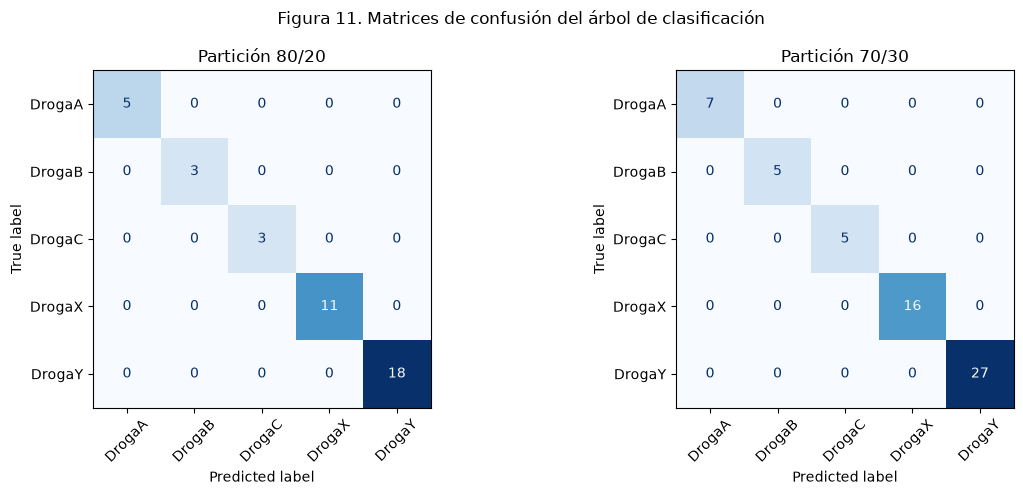

In [31]:
def graficar_matrices(predicciones, titulo):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
    for i, nombre in enumerate(predicciones, 1):
        ConfusionMatrixDisplay.from_predictions(
            particiones_pac[nombre]["ytst"], predicciones[nombre], cmap=plt.cm.Blues,
            ax=axes.flatten()[i-1], colorbar=False, xticks_rotation=45)
        axes.flatten()[i-1].set_title(f"Partición {nombre}")
    plt.suptitle(titulo)
    plt.tight_layout()
    plt.show()


graficar_matrices(predicciones_arbol, "Figura 11. Matrices de confusión del árbol de clasificación")

La hipótesis se cumple. En la Tabla 17 las tres métricas dan 1.0 en las dos particiones, y en la Figura 11 todos los casos están en la diagonal: acierta los 40 y los 60 pacientes de test, incluso en las drogas con menos pacientes.

### B5. Bayes Ingenuo

**Hipótesis previa:** el árbol llegó a 1.0 usando un corte de `Na_a_K` en 14.829. Pensamos que al discretizar `Na_a_K` ese corte se va a perder, así que esperamos un resultado menor al del árbol.

Comparamos `CategoricalNB`, con los datos discretizados en 3 y 5 intervalos, contra `GaussianNB` con las numéricas estandarizadas, como en el notebook de la unidad 5.

#### Discretización por cuantiles

Para los intervalos de igual frecuencia que pide el enunciado usamos `KBinsDiscretizer` con `strategy="quantile"`. No lo vimos en clase, pero es la opción de `scikit-learn` para esto. Lo ajustamos solo con el entrenamiento.

In [32]:
def discretizar(p, k):
    disc = KBinsDiscretizer(n_bins=k, encode="ordinal", strategy="quantile")
    disc.set_output(transform="pandas")
    disc.fit(p["Xtrn"][num_pac])
    Xtrn_disc = p["Xtrn"].copy()
    Xtst_disc = p["Xtst"].copy()
    Xtrn_disc[num_pac] = disc.transform(p["Xtrn"][num_pac])
    Xtst_disc[num_pac] = disc.transform(p["Xtst"][num_pac])
    return Xtrn_disc, Xtst_disc, disc


filas_bordes = []
for k in [3, 5]:
    Xtrn_disc, Xtst_disc, disc = discretizar(particiones_pac["80/20"], k)
    print(f"Pacientes por intervalo con {k} intervalos:")
    for i, col in enumerate(num_pac):
        print(f"   {col}: {Xtrn_disc[col].value_counts().sort_index().to_numpy()}")
        filas_bordes.append({"intervalos": k, "variable": col,
                             "límites": np.round(disc.bin_edges_[i], 2)})

print()
print("Tabla 18. Límites de los intervalos en la partición 80/20")
pd.DataFrame(filas_bordes)

Pacientes por intervalo con 3 intervalos:
   Edad: [53 53 54]
   Na_a_K: [53 53 54]
Pacientes por intervalo con 5 intervalos:
   Edad: [28 32 33 35 32]
   Na_a_K: [32 32 32 32 32]

Tabla 18. Límites de los intervalos en la partición 80/20


,intervalos,variable,límites
0,3,Edad,"[15.0, 37.0, 54.0, 74.0]"
1,3,Na_a_K,"[6.27, 11.42, 18.3, 38.25]"
2,5,Edad,"[15.0, 28.0, 39.0, 50.0, 61.5, 74.0]"
3,5,Na_a_K,"[6.27, 9.87, 12.81, 16.12, 22.76, 38.25]"


Cada intervalo queda con una cantidad parecida de pacientes. En la Tabla 18 vemos que el valor 15, que separaba a DrogaY (Tabla 13), queda dentro de un intervalo en los dos casos: entre 11.42 y 18.3 con 3 intervalos, y entre 12.81 y 16.12 con 5. Con 5 ese intervalo es más angosto.

#### Comparación de los enfoques

In [33]:
filas_bayes = []
predicciones_bayes = {}

for nombre in particiones_pac:
    p = particiones_pac[nombre]

    # GaussianNB sobre los valores continuos estandarizados
    gauss = GaussianNB()
    gauss.fit(p["Xtrn_std"], p["ytrn"])
    fila = calcular_metricas(nombre, p["ytst"], gauss.predict(p["Xtst_std"]))
    fila["configuración"] = "GaussianNB"
    filas_bayes.append(fila)

    # CategoricalNB sobre los continuos discretizados
    for k in [3, 5]:
        Xtrn_disc, Xtst_disc, disc = discretizar(p, k)
        categorico = CategoricalNB()
        categorico.fit(Xtrn_disc, p["ytrn"])
        pred = categorico.predict(Xtst_disc)
        fila = calcular_metricas(nombre, p["ytst"], pred)
        fila["configuración"] = f"CategoricalNB, {k} intervalos"
        filas_bayes.append(fila)
        if k == 5:
            predicciones_bayes[nombre] = pred

metricas_bayes = pd.DataFrame(filas_bayes)

print("Tabla 19. Resultados de Naive Bayes sobre los test")
metricas_bayes[["configuración", "partición", "Exactitud", "Precisión (macro)",
                "Exhaustividad (macro)"]].round(4)

Tabla 19. Resultados de Naive Bayes sobre los test


,configuración,partición,Exactitud,Precisión (macro),Exhaustividad (macro)
0,GaussianNB,80/20,0.8500,0.8311,0.9333
1,"CategoricalNB, 3 intervalos",80/20,0.8250,0.8305,0.8111
2,"CategoricalNB, 5 intervalos",80/20,0.9250,0.9262,0.9667
3,GaussianNB,70/30,0.8500,0.8083,0.9333
4,"CategoricalNB, 3 intervalos",70/30,0.8500,0.9021,0.8305
5,"CategoricalNB, 5 intervalos",70/30,0.9167,0.9000,0.9630


La hipótesis se cumple: en la Tabla 19 ninguna configuración llega al 1.0 del árbol.

La mejor es `CategoricalNB` con 5 intervalos (exactitud 0.9250 y 0.9167). `GaussianNB` da 0.8500 en las dos particiones y `CategoricalNB` con 3 intervalos da 0.8250 y 0.8500. Nos quedamos con 5 intervalos.

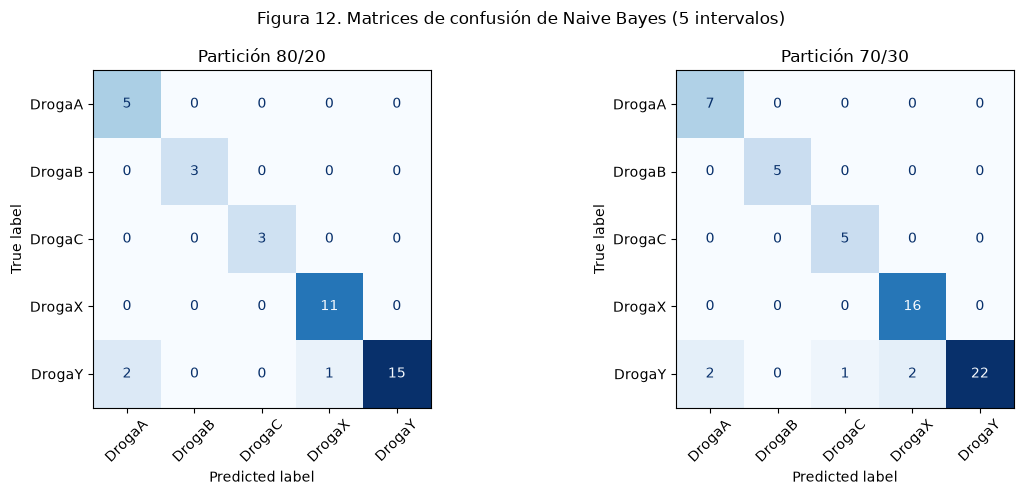

In [34]:
graficar_matrices(predicciones_bayes, "Figura 12. Matrices de confusión de Naive Bayes (5 intervalos)")

En la Figura 12 todos los errores están en la fila de DrogaY: 3 en la 80/20 (2 como DrogaA y 1 como DrogaX) y 5 en la 70/30 (2 como DrogaA, 1 como DrogaC y 2 como DrogaX). Las otras cuatro drogas no tienen errores. Esto coincide con lo que esperábamos al ver los intervalos de la Tabla 18.

### B6. k-NN

**Hipótesis previa:** en la Figura 7 DrogaY queda separada en `Na_a_K`, pero las otras drogas tienen rangos parecidos en las dos variables numéricas. Por eso esperamos un resultado por debajo del árbol.

Probamos los cinco valores de `n_neighbors` y las dos métricas que pide el enunciado con `GridSearchCV`, usando las variables estandarizadas.

In [35]:
grilla_knn = {"n_neighbors": [1, 3, 5, 7, 9],
              "metric": ["euclidean", "manhattan"]}

busquedas_knn = {}
for nombre in particiones_pac:
    p = particiones_pac[nombre]
    busqueda = GridSearchCV(KNeighborsClassifier(), grilla_knn, cv=5, scoring="accuracy")
    busqueda.fit(p["Xtrn_std"], p["ytrn"])
    busquedas_knn[nombre] = busqueda
    print(f"{nombre} -> {busqueda.best_params_} | exactitud de validación cruzada: {busqueda.best_score_:.4f}")

resultados_knn = pd.DataFrame(busquedas_knn["80/20"].cv_results_)

print()
print("Tabla 20. Combinaciones evaluadas en la partición 80/20")
resultados_knn.sort_values("rank_test_score")[
    ["param_n_neighbors", "param_metric", "mean_test_score"]
].round(4)

80/20 -> {'metric': 'euclidean', 'n_neighbors': 3} | exactitud de validación cruzada: 0.8875
70/30 -> {'metric': 'manhattan', 'n_neighbors': 9} | exactitud de validación cruzada: 0.8714

Tabla 20. Combinaciones evaluadas en la partición 80/20


,param_n_neighbors,param_metric,mean_test_score
1,3,euclidean,0.8875
9,9,manhattan,0.8875
5,1,manhattan,0.8812
2,5,euclidean,0.8688
6,3,manhattan,0.8688
4,9,euclidean,0.8688
7,5,manhattan,0.8688
0,1,euclidean,0.8688
8,7,manhattan,0.8688
3,7,euclidean,0.8438


Cada partición elige una combinación distinta: 3 vecinos con distancia euclídea en la 80/20 y 9 vecinos con Manhattan en la 70/30.

En la Tabla 20 dos combinaciones empatan en 0.8875 y otras seis quedan en 0.8688, así que los valores están muy cerca entre sí.

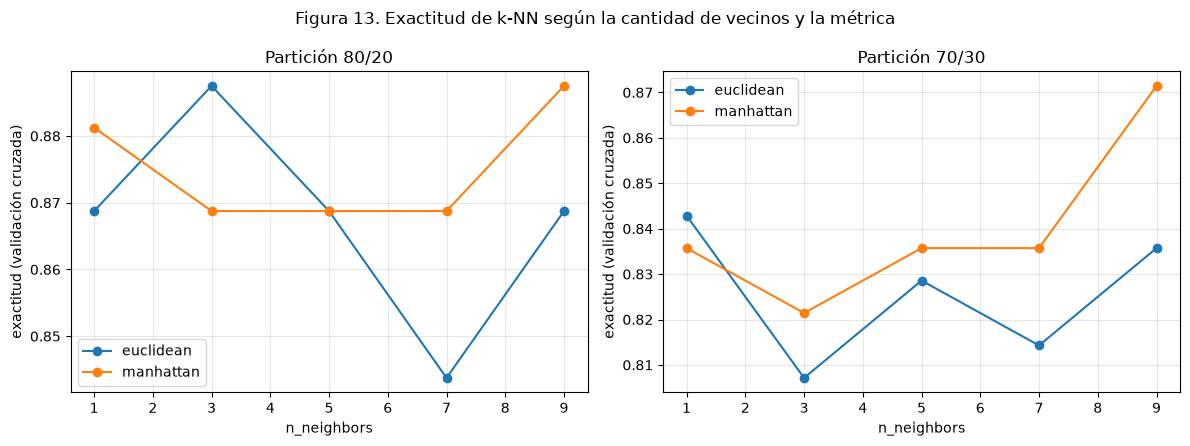

In [36]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(12, 4.5))

for i, nombre in enumerate(busquedas_knn, 1):
    ax = axes.flatten()[i-1]
    tabla = pd.DataFrame(busquedas_knn[nombre].cv_results_)
    for metrica in ["euclidean", "manhattan"]:
        sub = tabla[tabla["param_metric"] == metrica].sort_values("param_n_neighbors")
        ax.plot(sub["param_n_neighbors"], sub["mean_test_score"], "o-", label=metrica)
    ax.set_xlabel("n_neighbors")
    ax.set_ylabel("exactitud (validación cruzada)")
    ax.set_title(f"Partición {nombre}")
    ax.legend()
    ax.grid(alpha=0.3)

plt.suptitle("Figura 13. Exactitud de k-NN según la cantidad de vecinos y la métrica")
plt.tight_layout()
plt.show()

En la Figura 13 las curvas suben y bajan sin una tendencia clara. La exactitud va de 0.84 a 0.89 en la 80/20 y de 0.81 a 0.87 en la 70/30. Ninguna métrica gana siempre, aunque en las dos particiones Manhattan con 9 vecinos da el valor más alto.

#### Resultados sobre los conjuntos de test

In [37]:
filas_knn = []
predicciones_knn = {}

for nombre in particiones_pac:
    p = particiones_pac[nombre]
    predicciones_knn[nombre] = busquedas_knn[nombre].best_estimator_.predict(p["Xtst_std"])
    fila = calcular_metricas(nombre, p["ytst"], predicciones_knn[nombre])
    fila["vecinos"] = busquedas_knn[nombre].best_params_["n_neighbors"]
    fila["métrica"] = busquedas_knn[nombre].best_params_["metric"]
    filas_knn.append(fila)

metricas_knn = pd.DataFrame(filas_knn)

print("Tabla 21. Métricas de k-NN sobre los test")
metricas_knn[["partición", "vecinos", "métrica", "Exactitud", "Precisión (macro)",
              "Exhaustividad (macro)"]].round(4)

Tabla 21. Métricas de k-NN sobre los test


,partición,vecinos,métrica,Exactitud,Precisión (macro),Exhaustividad (macro)
0,80/20,3,euclidean,0.9000,0.8859,0.9556
1,70/30,9,manhattan,0.9167,0.9351,0.9304


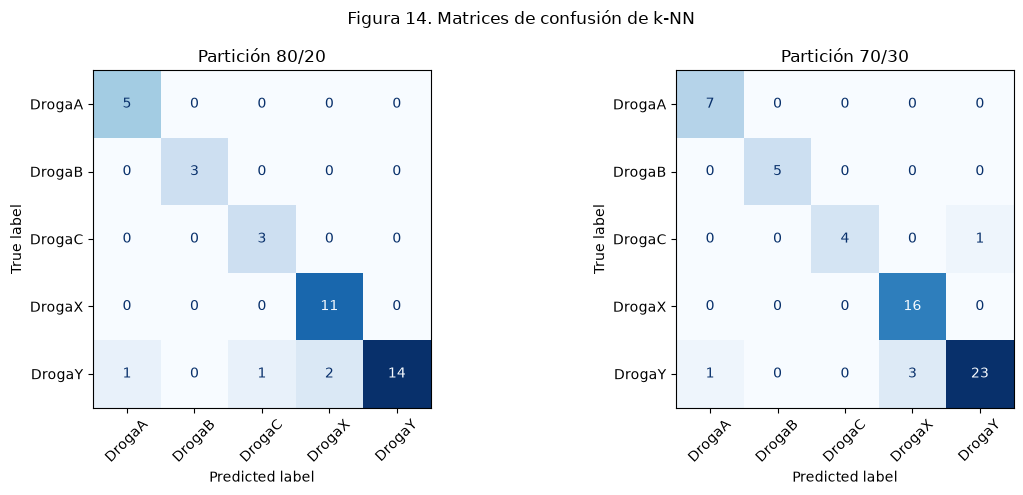

In [38]:
graficar_matrices(predicciones_knn, "Figura 14. Matrices de confusión de k-NN")

La hipótesis se cumple: en la Tabla 21 la exactitud es 0.9000 en la 80/20 y 0.9167 en la 70/30, por debajo del árbol.

En la Figura 14 los errores vuelven a estar sobre todo en la fila de DrogaY: 4 en la 80/20 y 4 en la 70/30. En la 70/30 además hay un paciente de DrogaC clasificado como DrogaY.

### B7. Comparación de los modelos

Juntamos el mejor modelo de cada algoritmo en los dos test.

In [39]:
comp_arbol = metricas_arbol.copy()
comp_arbol["modelo"] = "Árbol de decisión"
comp_arbol["configuración"] = "max_depth=5, sin poda"

comp_bayes = metricas_bayes[metricas_bayes["configuración"] == "CategoricalNB, 5 intervalos"].copy()
comp_bayes["modelo"] = "Bayes Ingenuo"

comp_knn = metricas_knn.copy()
comp_knn["modelo"] = "k-NN"
comp_knn["configuración"] = comp_knn["vecinos"].astype(str) + " vecinos, " + comp_knn["métrica"]

comparacion = pd.concat([comp_arbol, comp_bayes, comp_knn])

print("Tabla 22. Comparación de los tres clasificadores")
comparacion[["modelo", "configuración", "partición", "Exactitud", "Precisión (macro)",
             "Exhaustividad (macro)"]].round(4).reset_index(drop=True)

Tabla 22. Comparación de los tres clasificadores


,modelo,configuración,partición,Exactitud,Precisión (macro),Exhaustividad (macro)
0,Árbol de decisión,"max_depth=5, sin poda",80/20,1.0000,1.0000,1.0000
1,Árbol de decisión,"max_depth=5, sin poda",70/30,1.0000,1.0000,1.0000
2,Bayes Ingenuo,"CategoricalNB, 5 intervalos",80/20,0.9250,0.9262,0.9667
3,Bayes Ingenuo,"CategoricalNB, 5 intervalos",70/30,0.9167,0.9000,0.9630
4,k-NN,"3 vecinos, euclidean",80/20,0.9000,0.8859,0.9556
5,k-NN,"9 vecinos, manhattan",70/30,0.9167,0.9351,0.9304


Elegimos el árbol de decisión. En la Tabla 22 tiene 1.0 en las tres métricas y en las dos particiones, mientras que los otros dos quedan entre 0.8859 y 0.9667.

Entre Bayes y k-NN no vemos una diferencia clara: Bayes da mejor exactitud en la 80/20 (0.9250 contra 0.9000) y empatan en la 70/30 (0.9167).

También lo elegimos por interpretabilidad. En la Figura 9 se puede seguir cada decisión como una pregunta con un umbral. Con Bayes y k-NN no tenemos un gráfico así para explicar una predicción.

## Conclusiones

**Parte A.** La ganancia está muy relacionada con `RyD_Spend`: en la Figura 3 forman casi una recta y esa variable tiene una importancia de 0.989 en el árbol (Tabla 8). El árbol da un MAE de 997.20 y 949.77 (Tabla 9), chico al lado de la ganancia media de 118.675.

**Parte B.** `Na_a_K` identifica a DrogaY, `BP` separa a las demás en grupos y `Edad` separa DrogaA de DrogaB, mientras que `Sexo` no aparece en el árbol (Figuras 7, 8 y 9).

El árbol acertó todos los pacientes de los dos test (Tabla 17). Podarlo no ayudó: con `ccp_alpha` de 0.07 o más baja el f1 y se pierde al menos DrogaC (Tabla 16 y Figura 10). Bayes Ingenuo y k-NN quedaron entre 0.90 y 0.925 de exactitud (Tabla 22), con la mayoría de los errores en DrogaY (Figuras 12 y 14).

**Conclusión final.** Para clasificar las drogas elegimos el árbol de decisión, porque tiene las mejores métricas en las dos particiones y sus reglas se pueden leer en la Figura 9. Hay que tener en cuenta que los test son chicos (40 y 60 pacientes).